# PCD Assignment 02
## Image Enhancement Using Gamma Correction, Histogram Equalization, and CLAHE

**Course:** Pengolahan Citra Digital (PCD)  
**Student:** Yasyfin Haidar Pranaja Zuhri  
**Assignment:** Image Enhancement

---

### Objective

This notebook implements image enhancement on a basketball photograph. The original image is converted to a controlled **dark and low-contrast input**, then enhanced using:

1. **Gamma Correction**
2. **Histogram Equalization**
3. **Contrast Limited Adaptive Histogram Equalization (CLAHE)**

The results are evaluated visually, through intensity histograms, and using basic numerical statistics.

## 1. Introduction

Image enhancement improves the visibility of useful information in an image. Common problems include insufficient brightness, low contrast, excessive brightness, blur, and uneven illumination. In this experiment, the selected basketball photograph is intentionally transformed into a darker and lower-contrast grayscale image so that the enhancement process can be evaluated under a clear test condition.

Gamma Correction is included because the input is dark. Histogram Equalization is included as a global contrast-enhancement method, while CLAHE provides local contrast enhancement with a limit on amplification. The goal is not simply to make the image brighter, but to examine how each method changes brightness, contrast, and visible detail.

## 2. Import Libraries and Define Paths

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True

IMAGE_PATH = Path("images/original.jpg")
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

print("Input image:", IMAGE_PATH)
print("Results directory:", RESULTS_DIR)

Input image: images/original.jpg
Results directory: results


## 3. Load and Inspect the Original Image

The original photograph is loaded in grayscale because the selected enhancement methods operate on intensity values. The original image is kept as the reference, while a dark/low-contrast version is generated for the actual enhancement experiment.

Image shape: (1152, 2048)
Data type: uint8
Minimum intensity: 0
Maximum intensity: 255
Mean intensity: 96.34
Standard deviation: 65.91


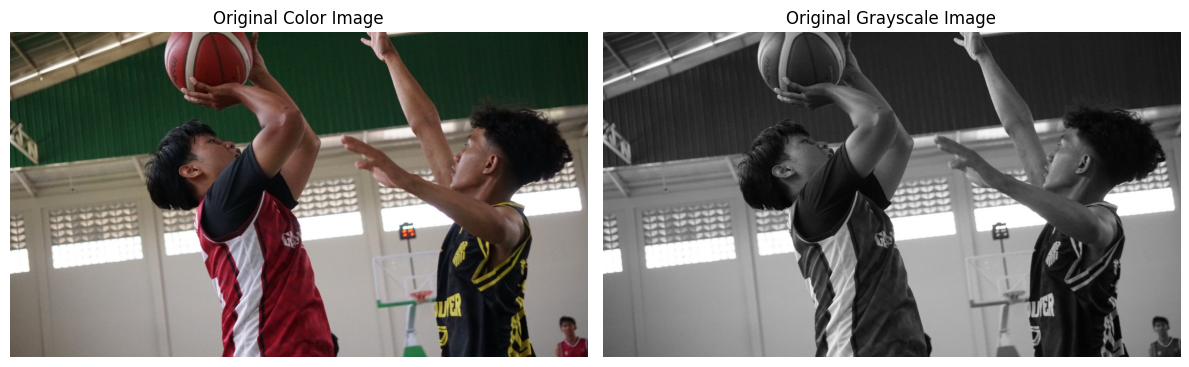

In [2]:
image_bgr = cv2.imread(str(IMAGE_PATH))
if image_bgr is None:
    raise FileNotFoundError(f"Could not read {IMAGE_PATH}")

gray_original = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

print("Image shape:", gray_original.shape)
print("Data type:", gray_original.dtype)
print("Minimum intensity:", gray_original.min())
print("Maximum intensity:", gray_original.max())
print("Mean intensity:", f"{gray_original.mean():.2f}")
print("Standard deviation:", f"{gray_original.std():.2f}")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
plt.title("Original Color Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray_original, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Create the Dark and Low-Contrast Test Image

To make the enhancement task reproducible, the original grayscale image is intentionally degraded using a linear intensity transformation:

\[
g(x) = lpha f(x) + eta
\]

where `alpha < 1` reduces contrast and a negative `beta` shifts the image toward darker values.

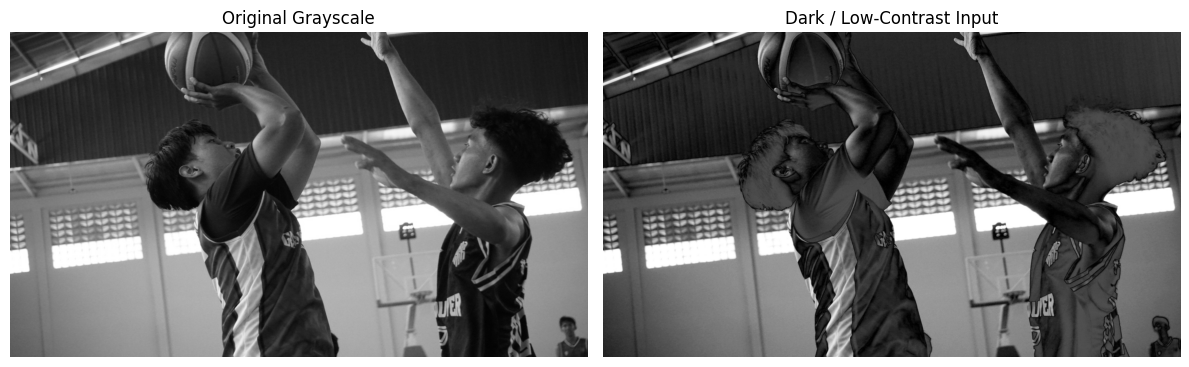

Input mean: 32.55
Input standard deviation: 24.03


In [3]:
alpha = 0.55
beta = -35

input_image = cv2.convertScaleAbs(gray_original, alpha=alpha, beta=beta)
cv2.imwrite(str(RESULTS_DIR / "input_dark_low_contrast.png"), input_image)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray_original, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(input_image, cmap="gray")
plt.title("Dark / Low-Contrast Input")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Input mean:", f"{input_image.mean():.2f}")
print("Input standard deviation:", f"{input_image.std():.2f}")

## 5. Histogram of the Input Image

A grayscale histogram shows how frequently each intensity value occurs. A compressed histogram indicates that the image uses a relatively narrow range of intensity values, which is a common characteristic of low-contrast images.

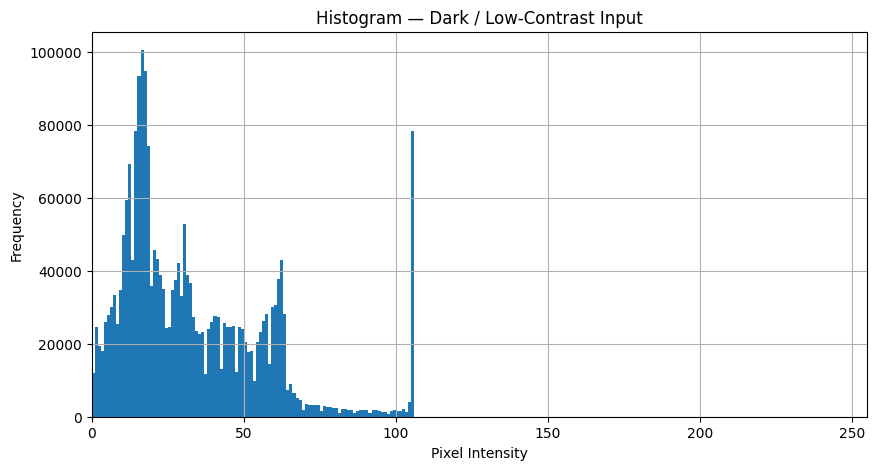

In [4]:
plt.figure(figsize=(10, 5))
plt.hist(input_image.ravel(), bins=256, range=(0, 256))
plt.title("Histogram — Dark / Low-Contrast Input")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim(0, 255)
plt.show()

## 6. Enhancement Method 1 — Gamma Correction

Gamma correction uses a nonlinear intensity transformation. For a dark image, a suitable setting can brighten lower intensity values and reveal details that are difficult to see.

The transformation used here is:

\[
g(x) = 255\left(rac{x}{255}ight)^{1/\gamma}
\]

with `gamma = 1.8`.

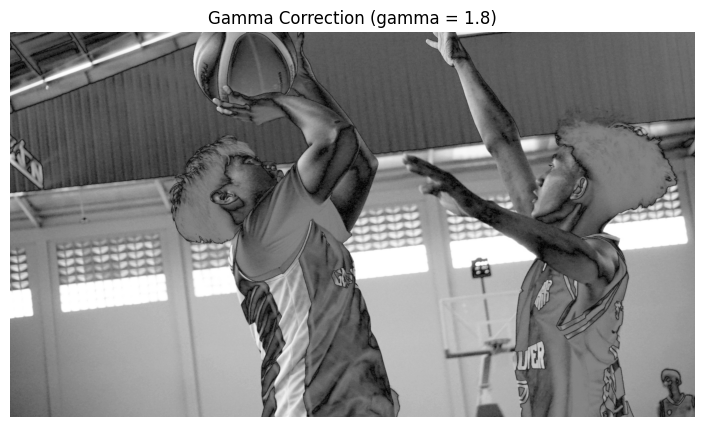

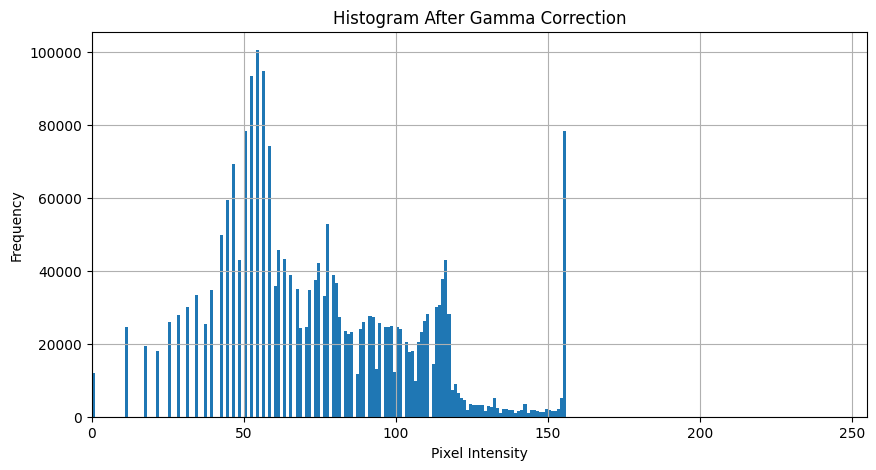

In [5]:
gamma = 1.8
lookup_table = np.array([((i / 255.0) ** (1 / gamma)) * 255 for i in range(256)]).astype(np.uint8)
gamma_result = cv2.LUT(input_image, lookup_table)

cv2.imwrite(str(RESULTS_DIR / "gamma_correction.png"), gamma_result)

plt.figure(figsize=(10, 5))
plt.imshow(gamma_result, cmap="gray")
plt.title(f"Gamma Correction (gamma = {gamma})")
plt.axis("off")
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(gamma_result.ravel(), bins=256, range=(0, 256))
plt.title("Histogram After Gamma Correction")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim(0, 255)
plt.show()

## 7. Enhancement Method 2 — Histogram Equalization

Histogram Equalization is a **global** contrast-enhancement method. It redistributes intensity values across the available grayscale range. This can make differences between nearby intensity levels more visible.

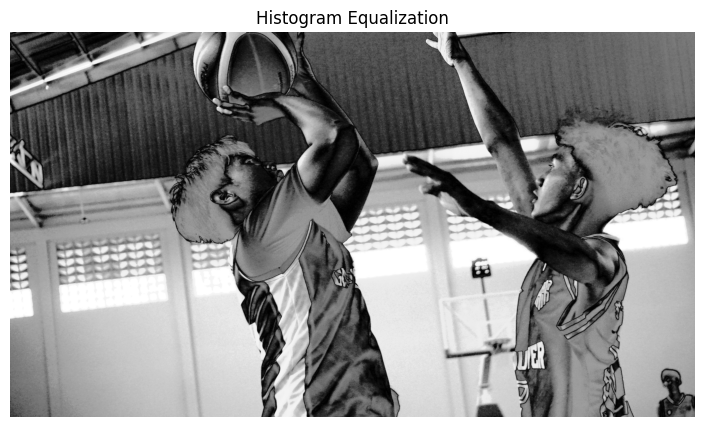

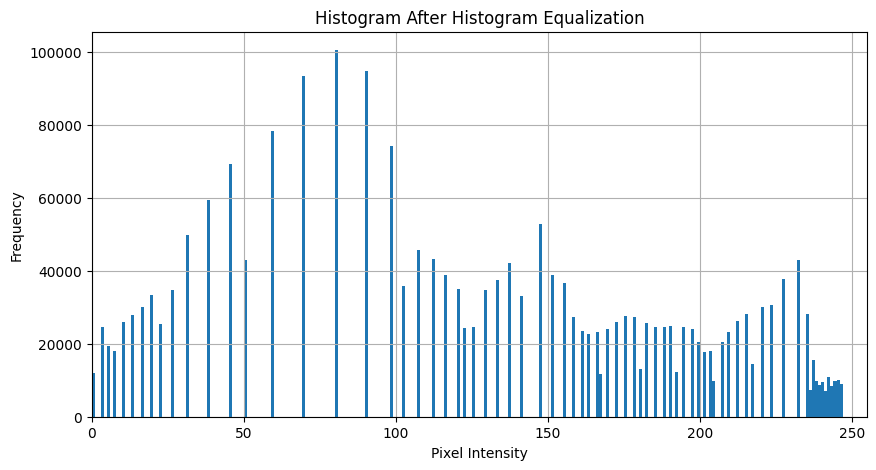

In [6]:
hist_eq_result = cv2.equalizeHist(input_image)
cv2.imwrite(str(RESULTS_DIR / "histogram_equalization.png"), hist_eq_result)

plt.figure(figsize=(10, 5))
plt.imshow(hist_eq_result, cmap="gray")
plt.title("Histogram Equalization")
plt.axis("off")
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(hist_eq_result.ravel(), bins=256, range=(0, 256))
plt.title("Histogram After Histogram Equalization")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim(0, 255)
plt.show()

## 8. Enhancement Method 3 — CLAHE

**CLAHE (Contrast Limited Adaptive Histogram Equalization)** performs histogram equalization locally. The image is divided into small tiles, and contrast is enhanced within each region. The contrast limit helps reduce excessive amplification.

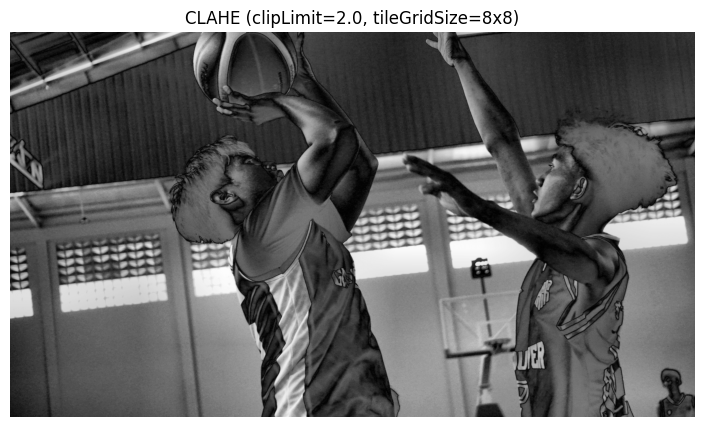

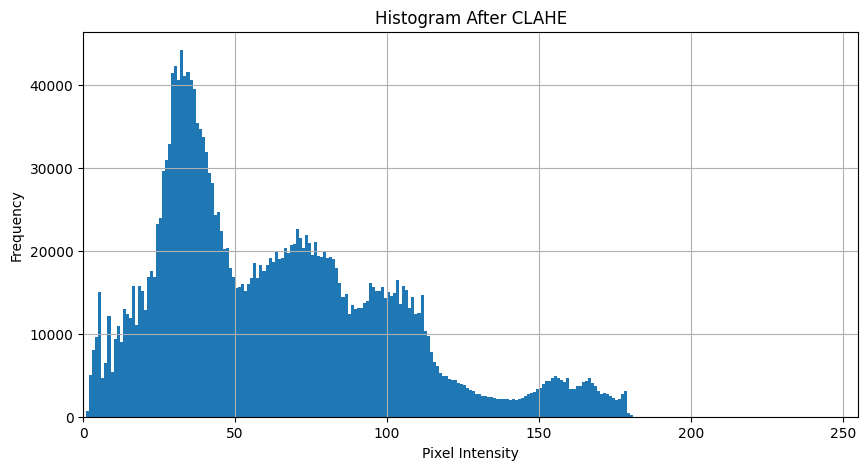

In [7]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_result = clahe.apply(input_image)
cv2.imwrite(str(RESULTS_DIR / "clahe.png"), clahe_result)

plt.figure(figsize=(10, 5))
plt.imshow(clahe_result, cmap="gray")
plt.title("CLAHE (clipLimit=2.0, tileGridSize=8x8)")
plt.axis("off")
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(clahe_result.ravel(), bins=256, range=(0, 256))
plt.title("Histogram After CLAHE")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim(0, 255)
plt.show()

## 9. Visual Comparison

The side-by-side comparison makes it easier to inspect brightness, global contrast, local detail, and possible artifacts.

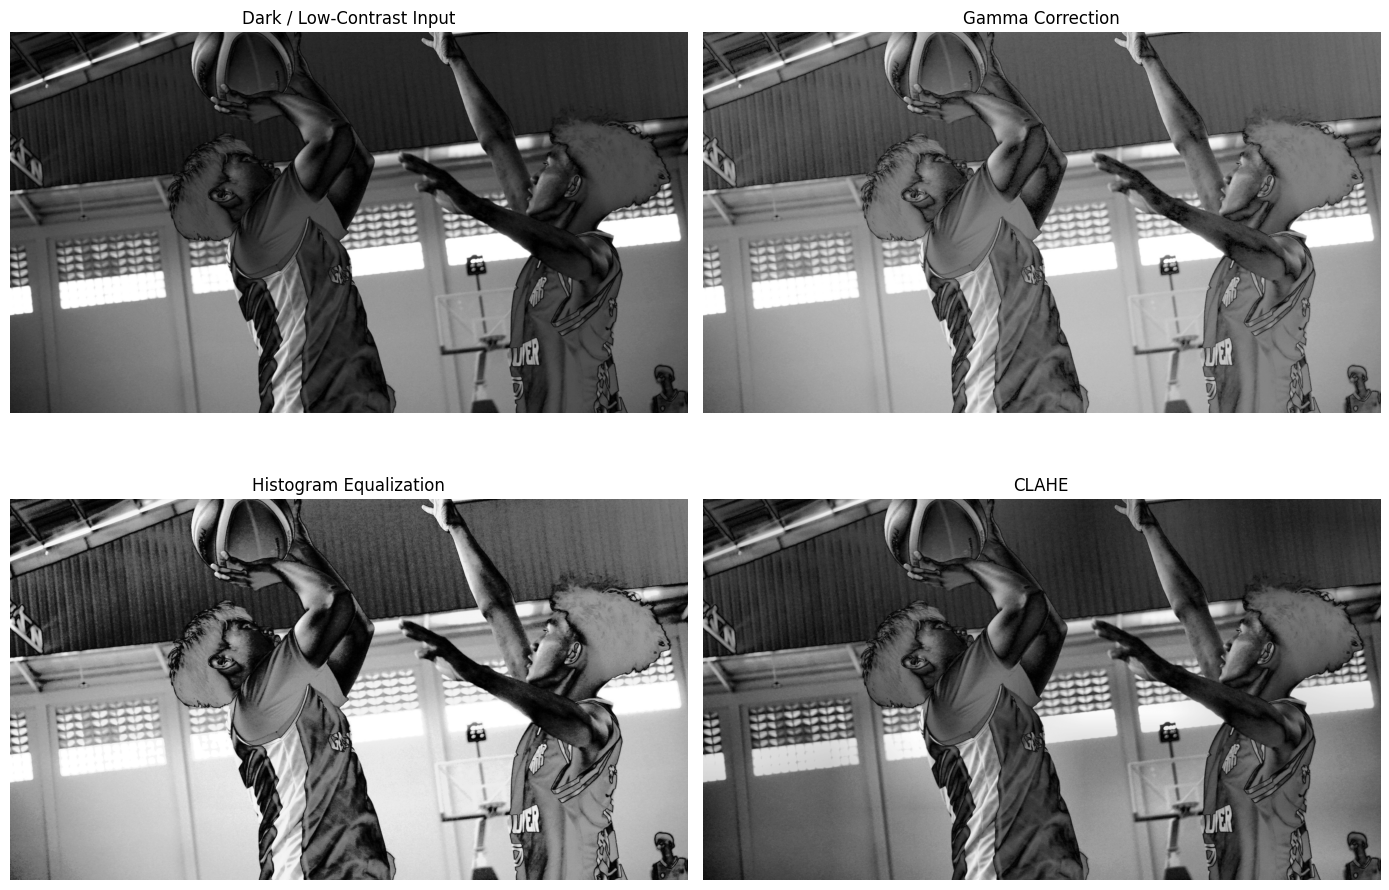

Saved: results/comparison.png


In [8]:
comparison_images = [
    ("Dark / Low-Contrast Input", input_image),
    ("Gamma Correction", gamma_result),
    ("Histogram Equalization", hist_eq_result),
    ("CLAHE", clahe_result),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (title, image) in zip(axes.ravel(), comparison_images):
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

comparison = np.hstack([input_image, gamma_result, hist_eq_result, clahe_result])
cv2.imwrite(str(RESULTS_DIR / "comparison.png"), comparison)
print("Saved:", RESULTS_DIR / "comparison.png")

## 10. Histogram Comparison

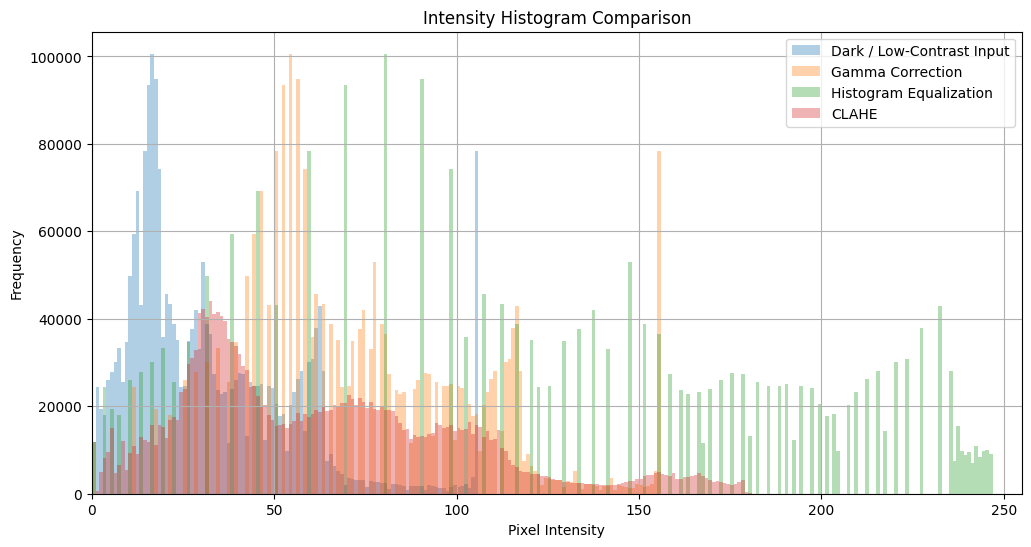

In [9]:
plt.figure(figsize=(12, 6))
for title, image in comparison_images:
    plt.hist(image.ravel(), bins=256, range=(0, 256), alpha=0.35, label=title)
plt.title("Intensity Histogram Comparison")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim(0, 255)
plt.legend()
plt.show()

## 11. Quantitative Comparison

The table below compares the minimum, maximum, mean, and standard deviation of the intensity values. Mean intensity is a simple indicator of brightness, while standard deviation gives a rough indication of intensity spread. These values support the visual analysis but do not replace it.

In [10]:
methods = {
    "Dark / Low-Contrast Input": input_image,
    "Gamma Correction": gamma_result,
    "Histogram Equalization": hist_eq_result,
    "CLAHE": clahe_result,
}

rows = []
for name, image in methods.items():
    rows.append({
        "Method": name,
        "Min": int(image.min()),
        "Max": int(image.max()),
        "Mean": round(float(image.mean()), 2),
        "Std Dev": round(float(image.std()), 2),
    })

df = pd.DataFrame(rows)
display(df)

,Method,Min,Max,Mean,Std Dev
0,Dark / Low-Contrast Input,0,105,32.55,24.03
1,Gamma Correction,0,155,75.35,32.44
2,Histogram Equalization,0,255,129.30,73.37
3,CLAHE,1,181,63.44,38.37


## 12. Analysis and Discussion

### Original and Test Input

The original photograph contains useful structures such as the basketball, players, clothing, court, and background. The controlled degradation reduces the intensity range and shifts the image toward darker values. As a result, some visual details become less distinct, providing a suitable test case for enhancement.

### Gamma Correction

Gamma Correction mainly addresses the brightness problem. Its nonlinear mapping gives greater emphasis to the lower intensity region, so dark areas become easier to inspect. The histogram shifts toward brighter values rather than being redistributed globally. This makes the method relatively direct when the dominant problem is darkness.

### Histogram Equalization

Histogram Equalization improves global contrast by redistributing intensities. Compared with the dark input, the resulting histogram should occupy a wider range. This can make edges and object boundaries easier to distinguish. However, because one global transformation is applied to the whole image, bright regions may become more intense and noise may also become more noticeable.

### CLAHE

CLAHE operates locally, so different areas of the image can receive different contrast adjustments. This is useful when the scene contains uneven illumination. The clipping limit prevents very strong local amplification, helping the result remain visually controlled. In this basketball scene, CLAHE can reveal local structures in darker areas while preserving more balanced contrast across regions.

### Quantitative Interpretation

The numerical table should be interpreted together with the images. A higher standard deviation may indicate a wider spread of intensities, but it does not automatically mean that the result is visually better. A useful enhancement should improve visibility of meaningful structures while avoiding excessive brightness, noise, or unnatural contrast.

### Overall Comparison

The methods have different purposes. Gamma Correction is mainly a brightness correction. Histogram Equalization is a global contrast correction. CLAHE is an adaptive local contrast correction. Therefore, the most appropriate method depends on the dominant characteristics of the input image. For images with darkness and uneven lighting, combining the visual inspection with histogram and statistical evidence gives a more reliable evaluation than using one metric alone.

## 13. Conclusion

This experiment successfully implements three image enhancement techniques on a controlled dark and low-contrast version of a basketball photograph. Gamma Correction improves brightness through nonlinear intensity mapping, Histogram Equalization expands global contrast, and CLAHE enhances local contrast while limiting excessive amplification.

The experiment demonstrates that image enhancement is not simply about increasing brightness. Each technique modifies the intensity distribution differently and therefore has different strengths. Visual comparison, histograms, and numerical statistics together provide a more complete analysis of enhancement performance.

The generated images are saved in the `results/` folder and can be uploaded directly to GitHub together with this notebook, source code, and report.

## 14. Output Files

After running the notebook, the following files are generated automatically:

- `results/input_dark_low_contrast.png`
- `results/gamma_correction.png`
- `results/histogram_equalization.png`
- `results/clahe.png`
- `results/comparison.png`

The full written report is also available as `REPORT.md`.